# Unsupervised machine learning

input =====> Output

ulabled\
clustering\
k-mean algorithm
------------------

In [176]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [177]:
df = pd.read_csv("/content/Mall_Customers.csv")
df

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


# Datta propertiees

In [178]:
df.shape

(200, 5)

In [179]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [180]:
df.isna().sum()

,0
CustomerID,0
Genre,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [181]:
df.columns

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

In [182]:
df.dtypes

,0
CustomerID,int64
Genre,object
Age,int64
Annual Income (k$),int64
Spending Score (1-100),int64


# Visualissation

<Axes: xlabel='count', ylabel='Genre'>

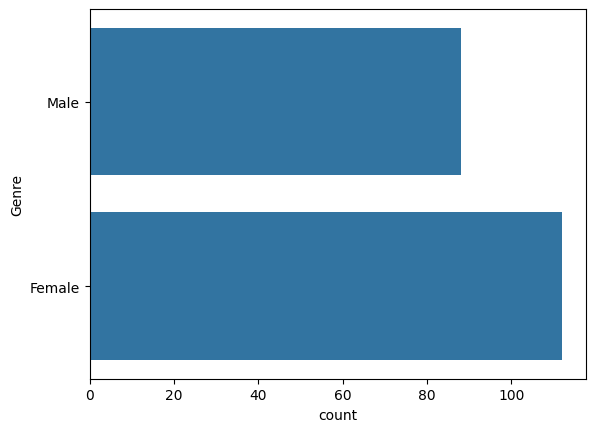

In [183]:
sns.countplot(data=df,y="Genre")

In [184]:
x = df.iloc[:,[2,3,4]]
x

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40
...,...,...,...
195,35,120,79
196,45,126,28
197,32,126,74
198,32,137,18


# K-Mean Clusturing

In [185]:
from sklearn.cluster import KMeans

In [186]:
wcss=[] # Craeate a list to store VArience
for i in range(1,11):
  data=KMeans(n_clusters=i,init='k-means++',random_state=42)  # mention Kmeans
  data.fit(x)
  wcss.append(data.inertia_)

In [187]:
wcss

[308812.7800000001,
 221087.1962719298,
 158744.97108013942,
 104366.151455562,
 97211.84353980474,
 68275.94428646985,
 51448.36126259325,
 44640.028048530425,
 42081.855308685335,
 38378.73890793209]

### Plot the Graph of Varience

Text(0, 0.5, 'Varience')

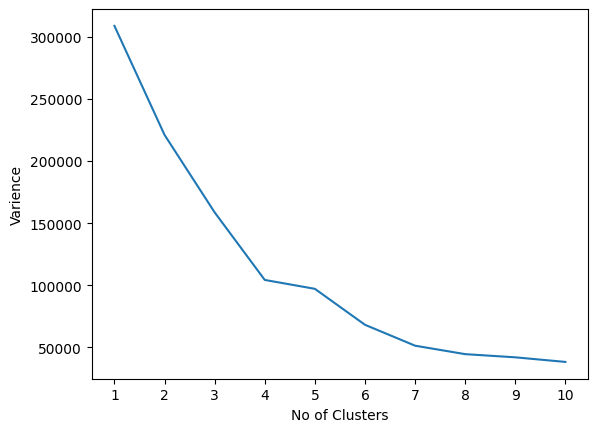

In [188]:
plt.plot(range(1,11),wcss)
plt.xlabel("No of Clusters")
plt.xticks(range(1,11))
plt.ylabel("Varience")

in this we take 7 as clusters count

Make Clusturs

In [189]:
data1 = KMeans(n_clusters=7,init='k-means++',random_state=42)
data1.fit(x)

KMeans(n_clusters=7, random_state=42)

In [190]:
y_pred = data1.predict(x)

In [191]:
y_pred

array([5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2,
       5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 0, 2, 5, 2,
       5, 2, 0, 6, 6, 6, 0, 6, 6, 0, 0, 0, 0, 0, 6, 0, 0, 6, 0, 0, 0, 6,
       0, 0, 6, 6, 0, 0, 0, 0, 0, 6, 0, 6, 6, 0, 0, 6, 0, 0, 6, 0, 0, 6,
       6, 0, 0, 6, 0, 6, 6, 6, 0, 6, 0, 6, 6, 0, 0, 6, 0, 6, 0, 0, 0, 0,
       0, 6, 6, 6, 6, 6, 0, 0, 0, 0, 6, 6, 6, 4, 6, 4, 6, 4, 3, 4, 3, 4,
       6, 4, 3, 4, 3, 4, 3, 4, 3, 4, 6, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4,
       3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4,
       3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1], dtype=int32)

In [192]:
x['clusters'] = y_pred

/tmp/ipykernel_2176/1063635667.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x['clusters'] = y_pred


In [193]:
x

,Age,Annual Income (k$),Spending Score (1-100),clusters
0,19,15,39,5
1,21,15,81,2
2,20,16,6,5
3,23,16,77,2
4,31,17,40,5
...,...,...,...,...
195,35,120,79,1
196,45,126,28,3
197,32,126,74,1
198,32,137,18,3


# Silhouette Score

calculate the accuracy of the clusters using by silhouette score.

best score is close to 1 but never be an negative value

In [194]:
from sklearn.metrics import silhouette_score



score = silhouette_score(x,y_pred)
score

np.float64(0.44809866306076435)

# Model BUilding

In [195]:
x

,Age,Annual Income (k$),Spending Score (1-100),clusters
0,19,15,39,5
1,21,15,81,2
2,20,16,6,5
3,23,16,77,2
4,31,17,40,5
...,...,...,...,...
195,35,120,79,1
196,45,126,28,3
197,32,126,74,1
198,32,137,18,3


In [196]:
input = x.iloc[:,:-1].values
output = x.iloc[:,-1].values

In [197]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(input,output,test_size=.3,random_state=42)

In [198]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

# KNN algorithm

In [199]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=7)
model.fit(x_train,y_train)

KNeighborsClassifier(n_neighbors=7)

In [200]:
y_pred = model.predict(x_test)

In [201]:
y_pred

array([6, 2, 5, 3, 3, 6, 6, 3, 3, 2, 0, 3, 4, 6, 3, 4, 0, 3, 0, 6, 6, 5,
       3, 6, 6, 0, 6, 0, 4, 6, 2, 5, 0, 6, 3, 0, 4, 4, 3, 0, 0, 1, 5, 5,
       6, 1, 2, 2, 4, 0, 6, 4, 2, 0, 0, 0, 3, 0, 3, 0], dtype=int32)

In [202]:
from sklearn.metrics import accuracy_score

score = accuracy_score(y_test,y_pred)
score

0.9833333333333333

# NAive Bayes

In [203]:
from sklearn.naive_bayes import GaussianNB

model_2 = GaussianNB()
model_2.fit(x_train,y_train)

GaussianNB()

In [204]:
y_pred2 = model_2.predict(x_test)

In [205]:
score1 = accuracy_score(y_test,y_pred)
score1

0.9833333333333333

# Decision Tree

In [206]:
from sklearn.tree import DecisionTreeClassifier

model_3 = DecisionTreeClassifier(criterion='entropy')
model_3.fit(x_train,y_train)

DecisionTreeClassifier(criterion='entropy')

In [207]:
y_pred3 = model_3.predict(x_test)

In [208]:
y_pred3

array([6, 2, 5, 3, 3, 6, 6, 3, 3, 2, 6, 3, 4, 6, 3, 4, 0, 3, 0, 6, 3, 5,
       3, 6, 6, 0, 6, 0, 4, 3, 2, 5, 0, 6, 3, 0, 4, 4, 3, 0, 0, 1, 5, 5,
       6, 1, 2, 2, 4, 0, 6, 4, 2, 3, 0, 0, 3, 0, 3, 0], dtype=int32)

In [209]:
score3 = accuracy_score(y_test,y_pred3)
score

0.9833333333333333

In [210]:
df1 = pd.DataFrame({
    "Model Name":["KNN","Naive Bayes","Decision Tree"],
    "Accuracy":[score*100,score1*100,score3*100]
})
df1

,Model Name,Accuracy
0,KNN,98.333333
1,Naive Bayes,98.333333
2,Decision Tree,93.333333


<Axes: xlabel='Model Name', ylabel='Accuracy'>

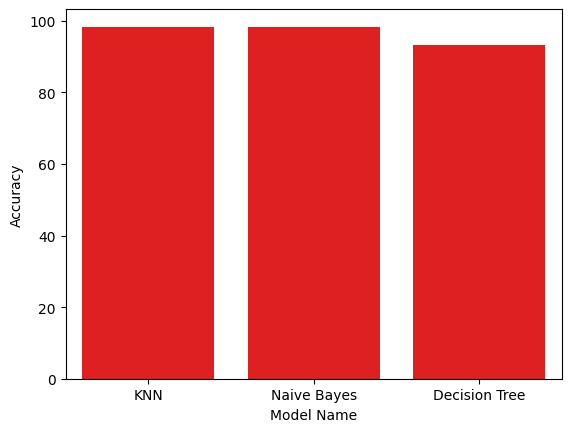

In [211]:
import seaborn as sns


sns.barplot(data=df1,x='Model Name',y="Accuracy",color='r')